<a href="https://colab.research.google.com/github/vikarpenko/apple-silicon-llm-speed/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vikarpenko/apple-silicon-llm-speed/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Local LLM Inference Speed on Apple Silicon

## 1. Question

### Research question

Can we predict how fast a local LLM runs on an Apple Silicon Mac (tokens per second), for a chip or a model that was not in the training data? And is machine learning better than a simple rule: speed = memory bandwidth / size of the active weights?

### What we predict

The target is the generation speed (tps, tokens/s) for one combination of chip, model, quantization and engine. We use only information that is known before running the model. This is a regression task.

We do not predict prompt processing speed. The dataset does not have it, and it depends mostly on GPU compute, not on memory bandwidth.

### Why it matters

Running an LLM on your own Mac is private, works offline and costs nothing per request. But before you download a big model (often tens of GB) or buy a new Mac, it is hard to know how fast it will be. New chips and new models come out all the time, so there is often no benchmark for your exact setup.

### What counts as an answer

1. The error on new chips and new models for: a constant baseline, the simple rule, and ML models. We say ML helps only if it beats the rule in most folds, not only on average.
2. Where the predictions are bad, and why.
3. Do the estimated (not measured) rows help when we add them to training? We never test on them.

---

## Setup

In [2]:
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import KFold, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

SEED = 42
##DATA_DIR = "data/"
sns.set_theme(style="whitegrid")

print("Python", sys.version.split()[0])
for lib in [np, pd, sklearn, sns]:
    print(lib.__name__, lib.__version__)

Python 3.13.18
numpy 2.4.6
pandas 2.2.3
sklearn 1.6.1
seaborn 0.13.2


---

## 2.1 Inspect the data

### Dataset

Source: [LLMCheck](https://llmcheck.net), a public collection of LLM speed results on Apple Silicon Macs ([benchmarks.csv](https://llmcheck.net/data/benchmarks.csv)). We downloaded it on 2026-11-02 and use this saved copy (llmcheck_benchmarks.csv), because the site changes often.

Each row is one result: one model, with one quantization, on one chip, with one engine.

| Column | Meaning |
|---|---|
| model | Model name, e.g. *Qwen 3.6-35B-A3B* |
| params | Model size as text: 27B for dense models, 35B-A3B for MoE (total / active) |
| quant | Quantization format, e.g. Q4_K_M, 4-bit, MXFP4 |
| chip | Apple Silicon chip, e.g. *M4 Pro* (only the name) |
| ram | Memory of the Mac, GB |
| engine | MLX, llama.cpp, LM Studio, Ollama, ... |
| tps | Target: generation speed, tokens/s |
| ttft | Time to first token, seconds |
| date | When the result was published |
| provenance | Where the number comes from (see below) |
| source, context, note | Link and test conditions (free text) |

provenance tells us which rows we can trust. "community" rows were measured by users, and "sourced" rows were measured and taken from model cards, papers or vendors. "estimated" rows were not measured: LLMCheck calculated them with a formula.

We also made two small helper tables. chips.csv has the bandwidth, GPU cores, generation and tier of each chip. It was made with the help of AI from Apple's specifications and LLMCheck data, and some values for the M5 and M6 chips are not verified yet (see the note column in the file). quant_bits.csv has the approximate bits per weight for each quantization format.

In [3]:
llm = pd.read_csv("/content/llmcheck_benchmarks.csv")
print("rows:", len(llm), "columns:", llm.shape[1], "duplicates:", llm.duplicated().sum())
llm.head()

rows: 480 columns: 13 duplicates: 0


,model,params,quant,chip,ram,engine,tps,ttft,date,provenance,source,context,note
0,Phi-4 Mini,3.8B,Q4_K_M,M5 Max,64.0,Ollama,168.0,NaN,2026-03,estimated,NaN,NaN,NaN
1,Phi-4 Mini,3.8B,Q4_K_M,M4 Pro,24.0,Ollama,86.0,NaN,2026-03,estimated,NaN,NaN,NaN
2,Phi-4 Mini,3.8B,Q4_K_M,M3,16.0,MLX,34.0,NaN,2026-02,estimated,NaN,NaN,NaN
3,Phi-4 Mini,3.8B,Q4_K_M,M2,8.0,Ollama,34.0,NaN,2026-01,estimated,NaN,NaN,NaN
4,Phi-4 Mini,3.8B,Q4_K_M,M1,16.0,Ollama,24.0,NaN,2025-12,estimated,NaN,NaN,NaN


### Missing values and column types

In [4]:
pd.DataFrame({"type": llm.dtypes,
              "missing": llm.isna().sum(),
              "unique": llm.nunique()})

,type,missing,unique
model,object,0,109
params,object,0,80
quant,object,0,40
chip,object,0,17
ram,float64,17,12
engine,object,0,6
tps,float64,0,244
ttft,float64,469,9
date,object,0,53
provenance,object,0,3


### Measured vs estimated rows

Estimated rows are not real measurements. If we train on them, the model learns LLMCheck's formula, not the real speed. So we look at measured rows (community + sourced) separately.

In [5]:
measured = llm[llm["provenance"] != "estimated"]

print(llm["provenance"].value_counts())
print("\nmeasured rows:", len(measured))
print("models:", measured["model"].nunique(), " chips:", measured["chip"].nunique())

provenance
estimated    287
community    146
sourced       47
Name: count, dtype: int64

measured rows: 193
models: 48  chips: 13


### Target distribution

count    193.0
mean      64.8
std       45.7
min        5.0
25%       34.5
50%       55.2
75%       82.0
max      387.0
Name: tps, dtype: float64


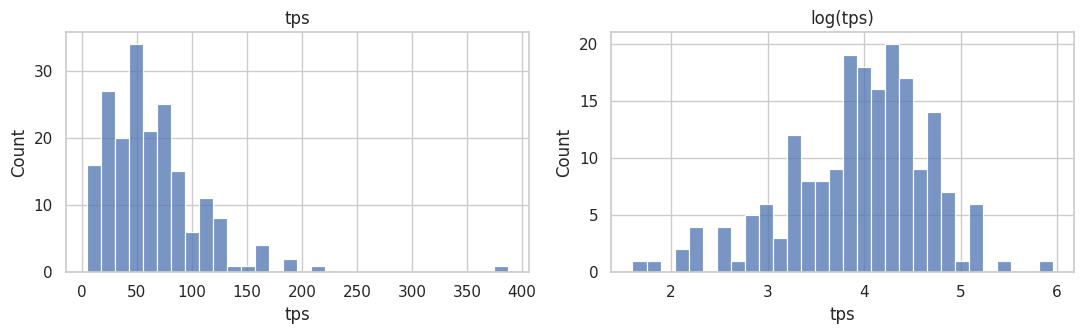

In [6]:
print(measured["tps"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(measured["tps"], bins=30, ax=axes[0])
axes[0].set_title("tps")
sns.histplot(np.log(measured["tps"]), bins=30, ax=axes[1])
axes[1].set_title("log(tps)")
plt.tight_layout()
plt.show()

Most models run at 20-100 tokens/s, and only a few are much faster (up to 387). The distribution has a long right tail. On the log scale it looks much more even.

So we train on log(tps). This also makes sense for two other reasons. Errors are relative: 10 tok/s is a big error at 20 tok/s, but small at 200. And the physics rule becomes linear: log(bandwidth / size) = log(bandwidth) - log(size).

### Text columns

In [7]:
for col in ["params", "quant", "engine"]:
    counts = measured[col].value_counts()
    print(f"{col}: {len(counts)} values")
    print(counts.head(8).to_string(), "\n")

print("ram:", measured["ram"].describe().round(0).to_dict())

params: 39 values
params
35B-A3B        25
27.8B          15
30B-A3B        14
74B-A9B        13
39.8B-A2.5B    12
4B             11
125B-A6B       10
24B-A2.45B      9 

quant: 35 values
quant
4-bit       60
Q4_K_M      24
oQ4e        13
unstated    12
Ternary      7
8-bit        7
IQ2_XXS      5
MXFP4        5 

engine: 6 values
engine
MLX          126
llama.cpp     41
LM Studio     18
Ollama         6
ds4            1
rec            1 

ram: {'count': 176.0, 'mean': 156.0, 'std': 156.0, 'min': 16.0, '25%': 48.0, '50%': 128.0, '75%': 256.0, 'max': 512.0}


params (39 values) and quant (35 values) are text in many styles (27B, 35B-A3B, 4-bit, Q4_K_M, ...), so we will turn them into numbers. engine is unbalanced: most rows use MLX, and ds4 and rec have only one row each, so we group these two as "other". ram goes from 16 to 512 GB with a median of 128 GB, so the data is mostly about high-end Macs. 17 rows have no RAM value.

### Rows per chip and per model

The same chip and the same model appear in many rows. This is important for validation: if a chip is in both train and test, the model has already "seen" it, and the error looks smaller than for a really new chip.

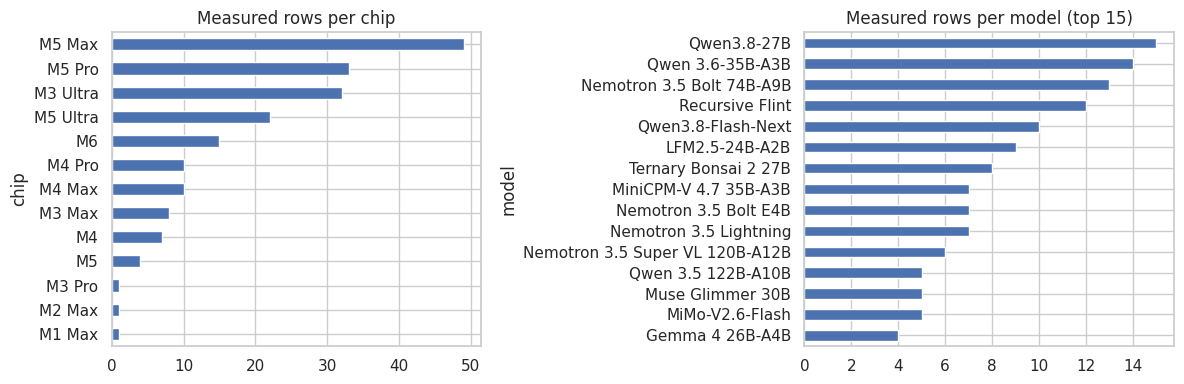

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
measured["chip"].value_counts().sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Measured rows per chip")
measured["model"].value_counts().head(15).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Measured rows per model (top 15)")
plt.tight_layout()
plt.show()

### Summary of the problems

1. Estimated rows. 287 of 480 rows (60%) are not measured, so we do not train on them (only in one experiment) and never test on them.
2. No chip specs. chip is only a name, so we add bandwidth, GPU cores, generation and tier from chips.csv.
3. Numbers stored as text. We turn params and quant into total / active parameters and bits per weight.
4. Missing values. 12 rows have quant = "unstated" (dropped), 17 rows have no ram (filled inside the pipeline), ttft is almost empty (dropped).
5. Uneven coverage. M5 Max has many rows, M1 Max, M2 Max and M3 Pro have only one. We keep them, but results for rare chips are less reliable.
6. Different test conditions. Different context lengths, engine versions, number of runs. We cannot fix this, so it is noise in the target.

---

## 2.2 Data cleaning

Here we turn the text columns into numbers that describe the chip and the model.

### Model size: total and active parameters

params looks like 27B or 35B-A3B. We take both numbers. For MoE models only the active part is read for each token, so it is the active size that matters for speed. Sometimes the active size is only in the model name, then we take it from there. If there is no active size, active = total.

In [9]:
def to_billions(text):
    if text.endswith("T"):
        return float(text[:-1]) * 1000
    return float(text[:-1])


def get_sizes(params, model):
    total_text, _, active_text = params.partition("-A")
    total = to_billions(total_text)
    if active_text:
        active = to_billions(active_text)
    else:
        found = re.search(r"-A(\d+(\.\d+)?)B", model)
        active = float(found.group(1)) if found else total
    return total, active


df = llm.copy()
sizes = [get_sizes(p, m) for p, m in zip(df["params"], df["model"])]
df["total_params_b"] = [s[0] for s in sizes]
df["active_params_b"] = [s[1] for s in sizes]
df["is_moe"] = df["active_params_b"] < df["total_params_b"]

df[["model", "params", "total_params_b", "active_params_b", "is_moe"]].drop_duplicates("params").head(8)

,model,params,total_params_b,active_params_b,is_moe
0,Phi-4 Mini,3.8B,3.8,3.8,False
5,Qwen 3.5 4B,4B,4.0,4.0,False
9,Gemma 4 E2B,2.3B,2.3,2.3,False
18,Gemma 4 26B-A4B,26B,26.0,4.0,True
21,Gemma 4 31B,31B,31.0,31.0,False
27,Qwen 3.5 9B,9B,9.0,9.0,False
31,Qwen 3 8B,8B,8.0,8.0,False
38,Mistral 7B,7B,7.0,7.0,False


### Quantization: bits per weight

We map each quantization format to an approximate number of bits per weight from quant_bits.csv. The values are not exact: for example, Q4_K_M also stores scales, so it is a bit more than 4 bits. Rows with quant = "unstated" get no value.

In [10]:
bits = pd.read_csv("/content/quant_bits.csv")
df = df.merge(bits, on="quant", how="left")

print("formats without bits:", df.loc[df["bits_per_weight"].isna(), "quant"].unique())

formats without bits: ['unstated']


### Chip characteristics

chip is only a name, so we add the specifications from chips.csv. We always use the full version of each chip. Some chips also have a cheaper version (for example, M4 Max with a 32-core GPU has 410 GB/s, not 546), but the dataset does not show which one was used.

In [11]:
chips = pd.read_csv("/content/chips.csv")
chips = chips[["chip", "generation", "tier", "gpu_cores", "bandwidth_gbs"]]
df = df.merge(chips, on="chip", how="left")

print("chips without specs:", df.loc[df["bandwidth_gbs"].isna(), "chip"].unique())
chips

chips without specs: []


,chip,generation,tier,gpu_cores,bandwidth_gbs
0,M1,1,base,8.0,68.0
1,M1 Pro,1,pro,16.0,200.0
2,M1 Max,1,max,32.0,400.0
3,M1 Ultra,1,ultra,64.0,800.0
4,M2,2,base,10.0,100.0
5,M2 Pro,2,pro,19.0,200.0
6,M2 Max,2,max,38.0,400.0
7,M2 Ultra,2,ultra,76.0,800.0
8,M3,3,base,10.0,100.0
9,M3 Pro,3,pro,18.0,150.0


### New features

active_gb is the size of the weights read for each token, and total_gb is the size of the whole model (both in GB). roofline_tps = bandwidth / active_gb is the physical limit: the chip cannot make a token faster than it can read all active weights once.

We group the rare engines (ds4, rec, 1 row each) as "other", remove the 12 "unstated" rows and drop the columns we do not use. We keep quant and note for the checks below, but they are not used as features.

In [12]:
df["active_gb"] = df["active_params_b"] * df["bits_per_weight"] / 8
df["total_gb"] = df["total_params_b"] * df["bits_per_weight"] / 8
df["roofline_tps"] = df["bandwidth_gbs"] / df["active_gb"]

main_engines = ["MLX", "llama.cpp", "Ollama", "LM Studio"]
df.loc[~df["engine"].isin(main_engines), "engine"] = "other"

df = df.dropna(subset=["bits_per_weight"])
df = df.drop(columns=["ttft", "source", "context", "date", "params"])

df_all = df.reset_index(drop=True)
df_measured = df[df["provenance"] != "estimated"].reset_index(drop=True)
df_estimated = df[df["provenance"] == "estimated"].reset_index(drop=True)
print("all rows:", len(df_all), " measured:", len(df_measured), " estimated:", len(df_estimated))

all rows: 468  measured: 181  estimated: 287


### Data quality check

Two simple physical checks: the measured speed cannot be higher than the roofline, and the model cannot be bigger than the Mac's memory.

In [13]:
faster = df_measured[df_measured["tps"] > df_measured["roofline_tps"]]
too_big = df_measured[df_measured["total_gb"] > df_measured["ram"]]

print("faster than the limit:", len(faster))
print("bigger than RAM:", len(too_big))
too_big[["model", "chip", "ram", "total_gb", "tps"]]

faster than the limit: 0
bigger than RAM: 1


,model,chip,ram,total_gb,tps
57,DeepSeek V4.1 Flash,M5 Max,128.0,181.47,29.6


No row is faster than the physical limit. One row is bigger than the Mac's memory: *DeepSeek V4.1 Flash* on a 128 GB M5 Max. Its note says the model was streamed from the SSD, so its speed does not depend on memory bandwidth. We remove this row.

In [14]:
df_measured = df_measured.drop(too_big.index).reset_index(drop=True)
print("measured rows:", len(df_measured))

measured rows: 180


### A run with a broken setup

One more row is not a normal measurement: *DeepSeek V4.1 Flash* on M3 Ultra at 6.5 tok/s. Its note says it used a custom runtime with an "immature loader". The same model on the same chip runs at about 20 tok/s with a normal runtime (oMLX). So this row shows a software problem, not the real speed of the chip, and we remove it.

In [15]:
broken = df_measured["note"].str.contains("immature loader", na=False)
print(df_measured.loc[broken, ["model", "chip", "quant", "tps", "note"]].to_string())

df_measured = df_measured[~broken].reset_index(drop=True)
print("measured rows:", len(df_measured), " models:", df_measured["model"].nunique(), " chips:", df_measured["chip"].nunique())

                  model      chip          quant   tps                                                                                        note
57  DeepSeek V4.1 Flash  M3 Ultra  4/8-bit mixed  6.53  PipeNetwork custom V4.1 runtime on mlx 0.32.2 / mlx-lm 0.31.3 (immature loader); 427.6 GB.
measured rows: 179  models: 47  chips: 13


---

## 3. Test set and validation scheme

### Test set

Before any modelling we put aside a test set: all rows of the two newest chips, M5 Ultra and M6. We do not use them for cross-validation, for choosing models or for tuning. We use them only once, at the end (section 8), to check the final models.

Why these chips: our question is about new chips, and these are the newest ones in the data. M5 Ultra also has much higher bandwidth (1228 GB/s) than any chip in the training part (max 819 GB/s), so this is a real test of whether a model can go beyond the range it saw.

In [16]:
TEST_CHIPS = ["M5 Ultra", "M6"]

is_test = df_measured["chip"].isin(TEST_CHIPS)
train_data = df_measured[~is_test].reset_index(drop=True)
test_data = df_measured[is_test].reset_index(drop=True)

df_estimated = df_estimated[~df_estimated["chip"].isin(TEST_CHIPS)].reset_index(drop=True)

X, y = train_data.drop(columns="tps"), train_data["tps"]
X_holdout, y_holdout = test_data.drop(columns="tps"), test_data["tps"]

print("train:", len(train_data), "rows,", train_data["chip"].nunique(), "chips")
print("test: ", len(test_data), "rows,", test_data["chip"].nunique(), "chips")

train: 148 rows, 11 chips
test:  31 rows, 2 chips


### Validation scheme (on the training part)

Rows are not independent: one chip or one model appears many times. So we use three schemes, all with 5 folds.

The main one is GroupKFold by chip: all rows of one chip are in the same fold, so this tests a new chip. GroupKFold by model does the same for a new model. We also show random KFold only to compare: there the same chip is often in train and test, so the error is too optimistic.

The training part has only 11 chips, so each fold has 2-3 chips, and folds have different sizes (M5 Max alone has 44 rows).

In [17]:
CV_SCHEMES = {
    "KFold": (KFold(n_splits=5, shuffle=True, random_state=SEED), None),
    "GroupKFold (chip)": (GroupKFold(n_splits=5), "chip"),
    "GroupKFold (model)": (GroupKFold(n_splits=5), "model"),
}

---

## 4. Metrics

1. MAE: average error in tokens/s. Easy to understand. *Main metric.*
2. MAPE: average error in percent. Fair for slow and fast models: 10 tok/s is a big error at 20 tok/s, but small at 200. *Main metric.*
3. RMSE: like MAE, but big errors count more. If RMSE is much bigger than MAE, the model sometimes makes big mistakes.
4. R2: how much of the variation the model explains (1 is perfect, 0 is like predicting the mean).
5. Within +-20%: the share of predictions with an error below 20%, i.e. how often the prediction is "good enough".

---

## 5. Baselines

All models are trained on log(tps) and we take exp() of the prediction. The reason is in section 6.

Most models predict log(tps) directly. The hybrid model (section 7) predicts something else: log(tps / roofline), i.e. how much of the physical limit the setup really reaches. The function fit_predict handles both cases. The function run_cv runs one model with one validation scheme and returns the scores for each fold and the predictions.

In [18]:
def fit_predict(model, kind, X_train, y_train, X_test):
    model = clone(model)
    if kind == "log":
        model.fit(X_train, np.log(y_train))
        return np.exp(model.predict(X_test))
    if kind == "hybrid":
        model.fit(X_train, np.log(y_train / X_train["roofline_tps"]))
        return X_test["roofline_tps"] * np.exp(model.predict(X_test))
    model.fit(X_train, y_train)
    return model.predict(X_test)


def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "MAPE": np.mean(np.abs(y_pred - y_true) / y_true),
            "R2": r2_score(y_true, y_pred)}


def run_cv(model, kind, cv_name, extra=None):
    cv, group_col = CV_SCHEMES[cv_name]
    groups = X[group_col] if group_col else None
    fold_scores = []
    predictions = pd.Series(index=y.index, dtype=float)

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups)):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

        if extra is not None:
            if group_col:
                extra_ok = extra[~extra[group_col].isin(X_test[group_col])]
            else:
                extra_ok = extra
            X_train = pd.concat([X_train, extra_ok.drop(columns="tps")])
            y_train = pd.concat([y_train, extra_ok["tps"]])

        pred = fit_predict(model, kind, X_train, y_train, X_test)
        train_pred = fit_predict(model, kind, X_train, y_train, X_train)
        predictions.iloc[test_idx] = pred

        row = scores(y_test, pred)
        row["train MAE"] = mean_absolute_error(y_train, train_pred)
        row["fold"] = fold + 1
        fold_scores.append(row)

    return pd.DataFrame(fold_scores), predictions


def compare(models, extra=None):
    rows = []
    for name, (model, kind) in models.items():
        for cv_name in CV_SCHEMES:
            folds, _ = run_cv(model, kind, cv_name, extra)
            row = {"model": name, "cv": cv_name}
            row.update(folds.drop(columns="fold").mean())
            rows.append(row)
    return pd.DataFrame(rows).round(2)

### Two baselines

The first baseline (Dummy) always predicts the median speed of the training data. Every useful model must beat it.

The second one is the physics rule. The real speed is always below the roofline, so we fit tps = a * roofline^b. On the log scale this is a straight line, log(tps) = log(a) + b * log(roofline), so a linear regression on one feature is enough.

In [19]:
physics = Pipeline([
    ("select", ColumnTransformer([("log", FunctionTransformer(np.log), ["roofline_tps"])])),
    ("model", LinearRegression()),
])

baselines = {
    "Dummy (median)": (DummyRegressor(strategy="median"), "log"),
    "Physics rule": (physics, "log"),
}
baseline_results = compare(baselines)
baseline_results.drop(columns="train MAE")

,model,cv,MAE,RMSE,MAPE,R2
0,Dummy (median),KFold,31.84,44.89,0.73,-0.09
1,Dummy (median),GroupKFold (chip),31.20,42.99,0.77,-0.15
2,Dummy (median),GroupKFold (model),31.83,45.69,0.73,-0.09
3,Physics rule,KFold,16.92,23.69,0.29,0.66
4,Physics rule,GroupKFold (chip),17.42,23.91,0.30,0.56
5,Physics rule,GroupKFold (model),17.11,23.74,0.30,0.67


The physics rule halves the error of the constant baseline: MAE about 17 tok/s instead of 31-32, and MAPE about 30% instead of about 75%. So bandwidth and model size explain most of the speed, but not all (R2 0.56-0.66).

The three schemes give almost the same result for the rule. This makes sense: it has only two parameters, so it cannot remember chips or models.

---

## 6. Preprocessing

Size and hardware features (bandwidth, GPU cores, RAM, parameters, GB) get log, because speed depends on their ratio, and log turns a ratio into a difference. generation and bits_per_weight stay as they are, and engine and tier get one-hot encoding. Missing ram is filled with the median. Then we scale the features, because Ridge is sensitive to their size. All of this is inside the pipeline, so it is fitted only on the training data in each fold.

In [20]:
LOG_FEATURES = ["bandwidth_gbs", "gpu_cores", "ram", "active_params_b",
                "total_params_b", "active_gb", "total_gb"]
NUM_FEATURES = ["generation", "bits_per_weight"]
CAT_FEATURES = ["engine", "tier"]


def make_pipeline(model, use_log=True, use_scaling=True):
    log_steps = [("fill", SimpleImputer(strategy="median"))]
    if use_log:
        log_steps.append(("log", FunctionTransformer(np.log)))
    num_steps = [("fill", SimpleImputer(strategy="median"))]
    if use_scaling:
        log_steps.append(("scale", StandardScaler()))
        num_steps.append(("scale", StandardScaler()))

    prep = ColumnTransformer([
        ("log_num", Pipeline(log_steps), LOG_FEATURES),
        ("num", Pipeline(num_steps), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])
    return Pipeline([("prep", prep), ("model", model)])

### Does each step help?

In [21]:
prep_variants = {
    "log features + scaling":   (make_pipeline(Ridge(alpha=10)), "log"),
    "no scaling":               (make_pipeline(Ridge(alpha=10), use_scaling=False), "log"),
    "no log on features":       (make_pipeline(Ridge(alpha=10), use_log=False), "log"),
    "no log on target":         (make_pipeline(Ridge(alpha=10)), "raw"),
}
prep_results = compare(prep_variants)
prep_results.drop(columns="train MAE")

,model,cv,MAE,RMSE,MAPE,R2
0,log features + scaling,KFold,13.48,20.58,0.22,0.77
1,log features + scaling,GroupKFold (chip),14.38,21.16,0.25,0.71
2,log features + scaling,GroupKFold (model),14.55,20.95,0.25,0.75
3,no scaling,KFold,13.56,21.08,0.23,0.76
4,no scaling,GroupKFold (chip),15.11,21.95,0.28,0.70
5,no scaling,GroupKFold (model),14.77,21.47,0.26,0.75
6,no log on features,KFold,21.62,35.10,0.37,0.36
7,no log on features,GroupKFold (chip),24.99,37.02,0.47,0.11
8,no log on features,GroupKFold (model),22.48,35.46,0.41,0.38
9,no log on target,KFold,17.94,28.15,0.46,0.57


Each step helps (GroupKFold by chip). Log on the features matters most: without it MAE goes from 14.4 to 25.0 and R2 drops from 0.71 to 0.11. Log on the target also helps a lot: without it MAE is 20.8 and MAPE is 60% instead of 25%. Scaling gives a small gain (14.4 instead of 15.1). So we keep all three steps.

---

## 7. Models

1. Ridge: after log, the physics rule is linear, so a linear model can learn it and also use other features.
2. Random Forest: can learn non-linear effects, but it cannot predict values outside the range it saw in training. This is a problem for new, faster chips.
3. Hybrid: Random Forest that learns only the correction to the physics rule, log(tps / roofline). The physics gives the main trend, and the forest only adjusts it.

In [22]:
def forest():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED)

models = {
    "Ridge": (make_pipeline(Ridge(alpha=10)), "log"),
    "Random Forest": (make_pipeline(forest()), "log"),
    "Hybrid (physics + RF)": (make_pipeline(forest()), "hybrid"),
}
model_results = compare(models)
model_results.drop(columns="train MAE")

,model,cv,MAE,RMSE,MAPE,R2
0,Ridge,KFold,13.48,20.58,0.22,0.77
1,Ridge,GroupKFold (chip),14.38,21.16,0.25,0.71
2,Ridge,GroupKFold (model),14.55,20.95,0.25,0.75
3,Random Forest,KFold,15.88,26.39,0.28,0.64
4,Random Forest,GroupKFold (chip),22.44,33.55,0.42,0.24
5,Random Forest,GroupKFold (model),17.20,27.37,0.31,0.62
6,Hybrid (physics + RF),KFold,12.85,22.64,0.19,0.73
7,Hybrid (physics + RF),GroupKFold (chip),16.87,29.46,0.26,0.23
8,Hybrid (physics + RF),GroupKFold (model),17.77,31.64,0.27,0.46


On new chips (GroupKFold by chip) Ridge is the best (MAE 14.4), better than the physics rule (17.4). Hybrid is second (16.9), but its RMSE is high (29.5), so it sometimes makes very big errors. Random Forest alone is the worst (22.5), even worse than the rule, because it cannot predict outside the range it saw.

On new models Ridge is also the best (14.7). Hybrid and Random Forest are a bit worse than the rule there (17.7 and 17.6 vs 17.2).

### Underfitting and overfitting

We compare the error on the training part with the error on the test part (GroupKFold by chip). If both errors are high and close to each other, the model is too simple (underfitting). If the train error is much lower than the test error, the model remembers the training data (overfitting).

In [23]:
all_models = {**baselines, **models}
fit_check = compare(all_models)
fit_check = fit_check[fit_check["cv"] == "GroupKFold (chip)"]
fit_check = fit_check[["model", "train MAE", "MAE"]].rename(columns={"MAE": "test MAE"})
fit_check = fit_check.reset_index(drop=True)
fit_check["test / train"] = (fit_check["test MAE"] / fit_check["train MAE"]).round(1)
fit_check

,model,train MAE,test MAE,test / train
0,Dummy (median),31.26,31.20,1.0
1,Physics rule,16.27,17.42,1.1
2,Ridge,12.23,14.38,1.2
3,Random Forest,9.12,22.44,2.5
4,Hybrid (physics + RF),7.12,16.87,2.4


Dummy and the physics rule have almost the same train and test error, and the error is high. They are too simple, so this is underfitting, but that is expected from a baseline. Ridge has a small gap (12.2 vs 14.4) and is the most balanced model. Random Forest and Hybrid have train errors about 2.5 times lower than test errors, so they overfit: they remember the training chips. min_samples_leaf=2 limits this a bit. For Hybrid the overfitting hurts less, because it learns only a correction and the physics part still works on new chips.

### Hyperparameter tuning

We try a few values with GroupKFold by chip, only on the training part. For each model we take the value with the lowest MAE. Then we train the final models with these values on the whole training part and test them once on the test chips (end of section 8).

The comparisons in section 8 still use the starting values (alpha=10, min_samples_leaf=2). If we used the tuned values there, the results would be too optimistic, because the values were chosen on the same folds.

In [24]:
tuning = []
for alpha in [0.1, 1, 10, 100]:
    folds, _ = run_cv(make_pipeline(Ridge(alpha=alpha)), "log", "GroupKFold (chip)")
    tuning.append({"model": "Ridge", "parameter": "alpha", "value": alpha, "MAE": folds["MAE"].mean()})

for leaf in [1, 2, 5, 10]:
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=SEED)
    for name, kind in [("Random Forest", "log"), ("Hybrid (physics + RF)", "hybrid")]:
        folds, _ = run_cv(make_pipeline(rf), kind, "GroupKFold (chip)")
        tuning.append({"model": name, "parameter": "min_samples_leaf", "value": leaf, "MAE": folds["MAE"].mean()})

tuning = pd.DataFrame(tuning)
tuning.round(2)

,model,parameter,value,MAE
0,Ridge,alpha,0.1,13.89
1,Ridge,alpha,1.0,13.96
2,Ridge,alpha,10.0,14.38
3,Ridge,alpha,100.0,18.51
4,Random Forest,min_samples_leaf,1.0,21.59
5,Hybrid (physics + RF),min_samples_leaf,1.0,16.21
6,Random Forest,min_samples_leaf,2.0,22.44
7,Hybrid (physics + RF),min_samples_leaf,2.0,16.87
8,Random Forest,min_samples_leaf,5.0,23.34
9,Hybrid (physics + RF),min_samples_leaf,5.0,17.97


In [25]:
best = tuning.loc[tuning.groupby("model")["MAE"].idxmin()].set_index("model")
print(best.round(2))

best_alpha = best.loc["Ridge", "value"]
best_leaf_rf = int(best.loc["Random Forest", "value"])
best_leaf_hybrid = int(best.loc["Hybrid (physics + RF)", "value"])

tuned_models = {
    "Ridge": (make_pipeline(Ridge(alpha=best_alpha)), "log"),
    "Random Forest": (make_pipeline(RandomForestRegressor(
        n_estimators=300, min_samples_leaf=best_leaf_rf, random_state=SEED)), "log"),
    "Hybrid (physics + RF)": (make_pipeline(RandomForestRegressor(
        n_estimators=300, min_samples_leaf=best_leaf_hybrid, random_state=SEED)), "hybrid"),
}

                              parameter  value    MAE
model                                                
Hybrid (physics + RF)  min_samples_leaf    1.0  16.21
Random Forest          min_samples_leaf    1.0  21.59
Ridge                             alpha    0.1  13.89


Tuning changes the results only a little. The best values are alpha=0.1 for Ridge (MAE 13.9 vs 14.4 with alpha=10) and min_samples_leaf=1 for both forests (Random Forest 21.6 vs 22.5, Hybrid 16.2 vs 16.9). The gains are small (0.5-0.9 tok/s), smaller than the std between folds, and the ranking of the models does not change. alpha=100 and large leaves are clearly worse.

---

## 8. Compare the experiments

### Adding estimated rows

We add the estimated rows to training and test only on measured rows. In the grouped schemes we do not add estimated rows of the test chip or model.

In [26]:
with_estimated = compare(models, extra=df_estimated)

mae_change = pd.DataFrame({
    "model": model_results["model"],
    "cv": model_results["cv"],
    "MAE measured only": model_results["MAE"],
    "MAE + estimated": with_estimated["MAE"],
})
mae_change["change"] = mae_change["MAE + estimated"] - mae_change["MAE measured only"]
mae_change.round(2)

,model,cv,MAE measured only,MAE + estimated,change
0,Ridge,KFold,13.48,14.11,0.63
1,Ridge,GroupKFold (chip),14.38,16.08,1.70
2,Ridge,GroupKFold (model),14.55,14.37,-0.18
3,Random Forest,KFold,15.88,13.88,-2.00
4,Random Forest,GroupKFold (chip),22.44,19.73,-2.71
5,Random Forest,GroupKFold (model),17.20,15.48,-1.72
6,Hybrid (physics + RF),KFold,12.85,14.25,1.40
7,Hybrid (physics + RF),GroupKFold (chip),16.87,16.00,-0.87
8,Hybrid (physics + RF),GroupKFold (model),17.77,18.83,1.06


Adding estimated rows does not give a clear improvement. Random Forest gets better in every scheme (on new chips from 22.5 to 19.7), because it needs more points to cover the range. But it is still worse than Ridge trained only on measured rows. For Ridge and Hybrid the changes are small (-0.9 to +1.7 tok/s) and go in both directions, and they are smaller than the std between folds. Estimated rows come from a formula, so they add little new information. We do not use them in the final models.

### Summary: MAE (mean +- std over folds)

In [27]:
fold_mae = []
oof_chip = {}
for name, (model, kind) in all_models.items():
    for cv_name in CV_SCHEMES:
        folds, pred = run_cv(model, kind, cv_name)
        folds["model"], folds["cv"] = name, cv_name
        fold_mae.append(folds[["model", "cv", "fold", "MAE"]])
        if cv_name == "GroupKFold (chip)":
            oof_chip[name] = pred
fold_mae = pd.concat(fold_mae)

summary = fold_mae.groupby(["model", "cv"], sort=False)["MAE"].agg(["mean", "std"]).round(1)
(summary["mean"].astype(str) + " +- " + summary["std"].astype(str)).unstack("cv")[list(CV_SCHEMES)]

cv,KFold,GroupKFold (chip),GroupKFold (model)
model,,,
Dummy (median),31.8 +- 7.2,31.2 +- 7.5,31.8 +- 2.5
Physics rule,16.9 +- 2.9,17.4 +- 5.6,17.1 +- 2.4
Ridge,13.5 +- 2.4,14.4 +- 3.2,14.6 +- 5.0
Random Forest,15.9 +- 4.1,22.4 +- 6.6,17.2 +- 6.3
Hybrid (physics + RF),12.9 +- 5.8,16.9 +- 7.6,17.8 +- 11.5


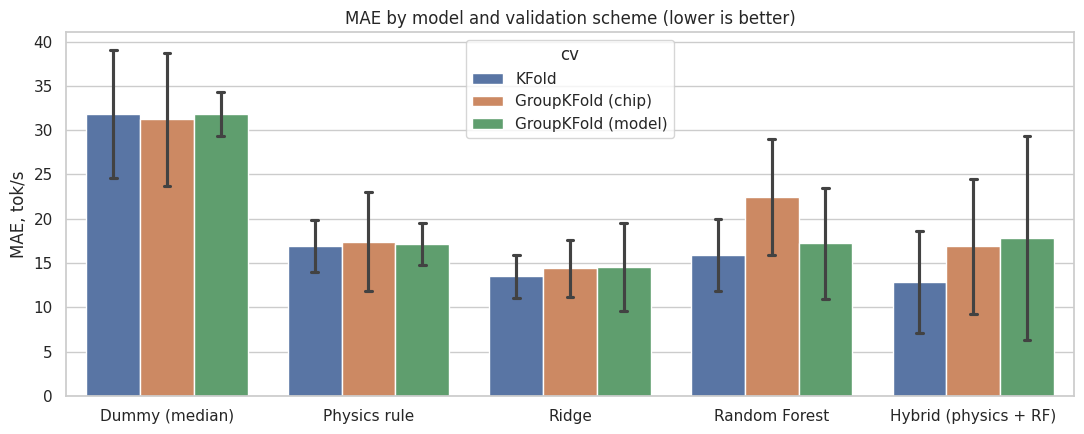

In [28]:
plt.figure(figsize=(11, 4.5))
sns.barplot(data=fold_mae, x="model", y="MAE", hue="cv", errorbar="sd", capsize=0.1)
plt.ylabel("MAE, tok/s")
plt.xlabel("")
plt.title("MAE by model and validation scheme (lower is better)")
plt.tight_layout()
plt.show()

The physics rule almost halves the error of the constant baseline (17.4 vs 31.2, 44% lower). On new chips Ridge (14.4) is about 17% better than the rule, Hybrid (16.9) is only a bit better, and Random Forest alone is worse than the rule. But the std between folds (2-9 tok/s) is about as big as the differences between Ridge, Hybrid and the rule, so the mean alone is not enough. We check fold by fold below.

### Fold by fold: ML model vs physics rule

Our rule from section 1: a model helps only if it beats the physics rule in most folds.

In [29]:
wide = fold_mae.pivot_table(index=["cv", "fold"], columns="model", values="MAE")
rows = []
for cv_name in CV_SCHEMES:
    for name in models:
        gain = wide.loc[cv_name, "Physics rule"] - wide.loc[cv_name, name]
        rows.append({"cv": cv_name, "model": name,
                     "folds better": f"{(gain > 0).sum()} / 5",
                     "mean gain, tok/s": round(gain.mean(), 2),
                     "std of gain": round(gain.std(), 2)})
pd.DataFrame(rows)

,cv,model,folds better,"mean gain, tok/s",std of gain
0,KFold,Ridge,5 / 5,3.44,0.82
1,KFold,Random Forest,3 / 5,1.04,2.56
2,KFold,Hybrid (physics + RF),4 / 5,4.06,3.89
3,GroupKFold (chip),Ridge,4 / 5,3.05,3.96
4,GroupKFold (chip),Random Forest,1 / 5,-5.01,10.05
5,GroupKFold (chip),Hybrid (physics + RF),3 / 5,0.56,4.92
6,GroupKFold (model),Ridge,4 / 5,2.56,3.13
7,GroupKFold (model),Random Forest,2 / 5,-0.09,4.53
8,GroupKFold (model),Hybrid (physics + RF),4 / 5,-0.66,9.57


Ridge wins in 4/5 folds both on new chips and on new models, with a mean gain of 2.5-3 tok/s. This is the only clear improvement, but the std of the gain is big (2-4 tok/s), so it is not very strong.

Hybrid wins in 3/5 folds on new chips, so formally it passes our rule. But the mean gain is only 0.6 tok/s with std 4.9, so this is not a real improvement. On new models it also wins in 3/5 folds, but the mean gain is negative. This shows that "most folds" alone is a weak rule: we also need a clear positive mean gain. With this stricter rule, only Ridge helps in cross-validation. Random Forest never helps.

### Predicted vs actual on unseen chips

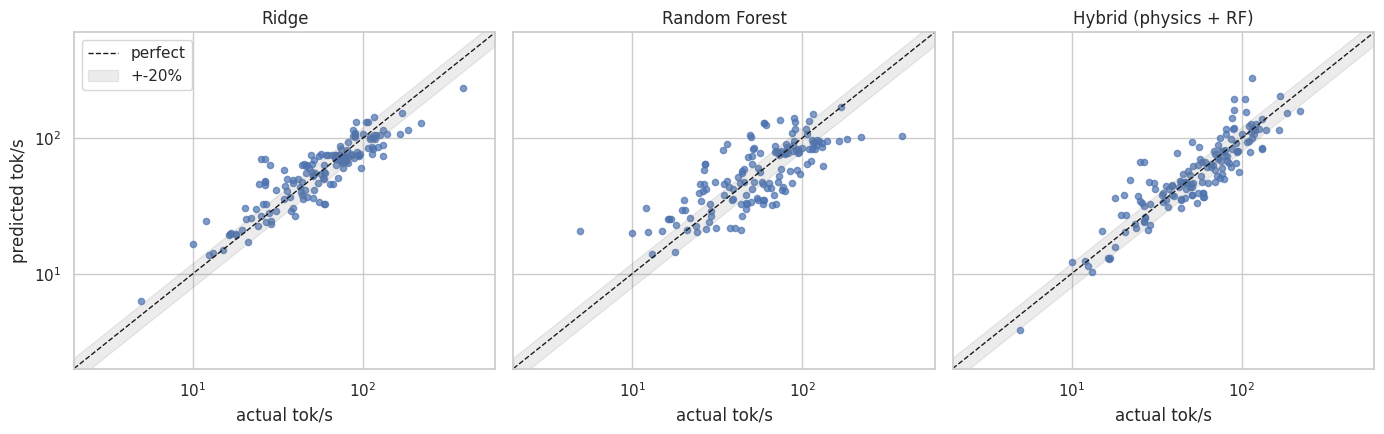

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
lims = [2, 600]
for ax, name in zip(axes, models):
    ax.scatter(y, oof_chip[name], s=20, alpha=0.7)
    ax.plot(lims, lims, "k--", lw=1, label="perfect")
    ax.fill_between(lims, [l * 0.8 for l in lims], [l * 1.2 for l in lims],
                    color="gray", alpha=0.15, label="+-20%")
    ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, title=name, xlabel="actual tok/s")
axes[0].set_ylabel("predicted tok/s")
axes[0].legend()
plt.tight_layout()
plt.show()

Ridge and Hybrid follow the diagonal for most points. Random Forest shows typical tree behaviour: its predictions are pushed to the middle of the range, so very fast runs are predicted too slow. All three models predict some slow runs (below 20 tok/s) too fast. We look at the biggest errors in section 9.

### Share of predictions within 20% (unseen chips)

In [31]:
within_20 = {name: (np.abs(pred - y) / y <= 0.2).mean() for name, pred in oof_chip.items()}
pd.Series(within_20).round(2).to_frame("within 20%")

,within 20%
Dummy (median),0.22
Physics rule,0.46
Ridge,0.55
Random Forest,0.33
Hybrid (physics + RF),0.53


About half of Ridge and Hybrid predictions are within 20% of the real speed (55% and 53%), compared with 46% for the physics rule and 32% for Random Forest.

### Final check on the test set (M5 Ultra and M6)

The final models use the tuned values. Each model is trained on the whole training part and tested once on the test chips. The test chips were not used for any choice before this.

In [32]:
final_models = {**baselines, **tuned_models}

test_rows = []
test_pred = {}
for name, (model, kind) in final_models.items():
    pred = fit_predict(model, kind, X, y, X_holdout)
    test_pred[name] = pred
    row = {"model": name}
    row.update(scores(y_holdout, pred))
    row["within 20%"] = (np.abs(pred - y_holdout) / y_holdout <= 0.2).mean()
    test_rows.append(row)
pd.DataFrame(test_rows).round(2)

,model,MAE,RMSE,MAPE,R2,within 20%
0,Dummy (median),33.91,47.72,1.25,-0.00,0.26
1,Physics rule,13.55,21.28,0.22,0.80,0.52
2,Ridge,13.59,18.83,0.28,0.84,0.42
3,Random Forest,22.48,33.10,0.36,0.52,0.26
4,Hybrid (physics + RF),10.53,16.64,0.18,0.88,0.61


In [33]:
per_chip = pd.DataFrame({name: (np.abs(pred - y_holdout)).groupby(X_holdout["chip"]).mean()
                         for name, pred in test_pred.items()})
per_chip.round(1)

,Dummy (median),Physics rule,Ridge,Random Forest,Hybrid (physics + RF)
chip,,,,,
M5 Ultra,37.0,17.7,16.9,30.6,12.2
M6,28.4,6.0,7.6,7.7,7.6


On the test chips the result is different from cross-validation. Hybrid is the best: MAE 10.6 vs 13.6 for the physics rule, and 61% of predictions within 20% (rule: 52%). It is much better on M5 Ultra (12.1 vs 17.7) and a bit worse than the rule on M6 (7.7 vs 6.0).

Ridge has the same MAE as the rule here (13.6), but by the other main metric it is worse: MAPE 28% vs 22%, and only 42% of predictions within 20% (rule: 52%). So the advantage of Ridge from cross-validation does not show on the test chips. Random Forest is very bad on M5 Ultra (30.6 tok/s), because its bandwidth is far above the training range. This is the problem we expected.

The test set is small (31 rows, 2 chips), so this is one result, not a reliable estimate, and it is not enough to choose a winner. It only shows that a model that is good in cross-validation is not always good on a really new chip. On these two chips building on physics worked better, but we cannot say that this is true for new chips in general.

---

## 9. Error analysis

We look at the errors of the hybrid model on unseen chips (cross-validation predictions on the training part).

In [34]:
err = X[["model", "chip", "engine", "is_moe", "active_gb"]].copy()
err["actual"] = y
err["predicted"] = oof_chip["Hybrid (physics + RF)"].round(1)
err["ratio"] = (err["predicted"] / err["actual"]).round(2)
err["error_%"] = ((err["ratio"] - 1).abs() * 100).round(0)

print("10 worst predictions:")
err.sort_values("error_%", ascending=False).head(10)

10 worst predictions:


,model,chip,engine,is_moe,active_gb,actual,predicted,ratio,error_%
46,Qwen3.8-Flash-Next,M3 Ultra,MLX,True,3.375000,25.10,66.5,2.65,165.0
45,Qwen3.8-Flash-Next,M3 Ultra,MLX,True,3.375000,26.50,66.5,2.51,151.0
132,LFM2.5-24B-A2B,M3 Ultra,MLX,True,1.378125,115.60,277.7,2.40,140.0
2,GLM 5.2,M3 Ultra,LM Studio,True,7.800000,22.00,49.1,2.23,123.0
82,Recursive Flint,M3 Ultra,MLX,True,1.406250,90.60,194.6,2.15,115.0
54,Muse Spark Open,M3 Ultra,llama.cpp,True,13.807500,18.00,36.1,2.01,101.0
40,DeepSeek V4.1 Flash,M3 Ultra,MLX,True,9.000000,20.23,38.3,1.89,89.0
80,Recursive Flint,M3 Ultra,MLX,True,1.406250,104.50,194.6,1.86,86.0
59,Nemotron 3.5 Bolt 74B-A9B,M3 Ultra,llama.cpp,True,5.456250,41.61,77.0,1.85,85.0
81,Recursive Flint,M3 Ultra,MLX,True,5.000000,51.30,93.0,1.81,81.0


In [35]:
by_chip = err.groupby("chip").agg(rows=("actual", "size"), mean_error_pct=("error_%", "mean"),
                                  median_ratio=("ratio", "median"))
by_chip.sort_values("mean_error_pct", ascending=False).round(2)

,rows,mean_error_pct,median_ratio
chip,,,
M3 Ultra,30,57.40,1.38
M3 Pro,1,26.00,0.74
M4 Max,9,23.56,1.12
M1 Max,1,19.00,1.19
M2 Max,1,19.00,0.81
M4,7,18.71,0.91
M5 Pro,33,18.67,0.92
M5 Max,44,16.98,0.91
M3 Max,8,16.50,1.06


In [36]:
not_m3_ultra = err["chip"] != "M3 Ultra"
pd.DataFrame({
    "rows": err.groupby("is_moe").size(),
    "mean_error_pct": err.groupby("is_moe")["error_%"].mean(),
    "mean_error_pct without M3 Ultra": err[not_m3_ultra].groupby("is_moe")["error_%"].mean(),
}).round(1)

,rows,mean_error_pct,mean_error_pct without M3 Ultra
is_moe,,,
False,39,16.5,16.4
True,109,29.1,18.3


Is the M3 Ultra error caused by the chip itself, or by our model? M3 Ultra is the only Ultra chip in the training part, so in its fold the model sees tier = ultra for the first time. To check this, we look at two things that do not depend on tier. The first is the efficiency in the data, with no model at all: efficiency = tps / roofline_tps, the share of the physical limit that the chip really reaches. The second is the physics rule, which uses only the roofline and never sees tier (ratio = predicted / actual).

In [37]:
eff = train_data["tps"] / train_data["roofline_tps"]
check = pd.DataFrame({"rows": eff.groupby(train_data["chip"]).size(),
                      "median efficiency": eff.groupby(train_data["chip"]).median(),
                      "physics median ratio": (oof_chip["Physics rule"] / y).groupby(X["chip"]).median()})
check.sort_values("median efficiency").round(2)

,rows,median efficiency,physics median ratio
chip,,,
M1 Max,1,0.26,1.43
M2 Max,1,0.31,1.32
M3 Ultra,30,0.33,1.38
M5 Max,44,0.39,0.89
M5,4,0.40,1.25
M4 Max,9,0.43,0.94
M3 Max,8,0.44,0.95
M4 Pro,10,0.46,0.98
M5 Pro,33,0.52,0.78


How noisy is the data? We take setups that were measured more than once (same model, chip, quant and engine) and see how far each result is from the median of its group.

In [38]:
keys = ["model", "chip", "quant", "engine"]
group_median = df_measured.groupby(keys)["tps"].transform("median")
group_size = df_measured.groupby(keys)["tps"].transform("size")
repeated = group_size > 1
deviation = (df_measured["tps"] - group_median).abs() / group_median
print("repeated rows:", repeated.sum())
print(f"mean deviation from the group median: {deviation[repeated].mean():.1%}")

reps = df_measured[repeated].assign(deviation=deviation[repeated].round(2))
reps.sort_values("deviation", ascending=False)[keys + ["tps", "deviation"]].head(6)

repeated rows: 27
mean deviation from the group median: 9.6%


,model,chip,quant,engine,tps,deviation
60,Qwen3.8-Flash-Next,M5 Max,oQ4e,MLX,28.50,0.51
56,DeepSeek V4.1 Flash,M3 Ultra,oQ4e,MLX,20.23,0.31
144,DeepSeek V4.1 Flash,M3 Ultra,oQ4e,MLX,38.70,0.31
135,Qwen 3.6-35B-A3B,M5 Pro,4-bit,MLX,94.30,0.21
131,Qwen3.8-Flash-Next,M5 Max,oQ4e,MLX,69.70,0.19
87,MiMo-V2.6-Flash,M5 Ultra,4-bit,MLX,61.70,0.11


The errors are not random. We see three patterns:

1. M3 Ultra. All 10 worst predictions are on M3 Ultra, and its mean error (57%) is 2-4 times higher than on other chips (14-26%). The model predicts it too fast (median ratio 1.38). The check above suggests that the problem is not only in our model. In the data M3 Ultra reaches only 33% of its roofline, while the chips with many rows reach 39-61% (only M1 Max and M2 Max are lower, with one row each). The physics rule, which never sees tier, also predicts M3 Ultra too fast (ratio 1.38). But this is not a proof: on M3 Ultra mostly large MoE models were measured, so the low efficiency may also come from this set of models. We did not compare the same models on different chips. One possible reason is that an Ultra chip is two chips joined together and cannot use its full bandwidth, but this is a hypothesis.
2. MoE models. All 10 worst predictions are MoE models, and on average the error for MoE is higher than for dense models (29% vs 17%). But this pattern mostly comes from M3 Ultra: without M3 Ultra the error is almost the same (18% for MoE vs 16% for dense). Also, the worst MoE rows have very different active sizes (1.4 to 13.8 GB), so the problem is not only very small active weights. So we cannot say that MoE models are harder to predict in general.
3. Noise in the data. Repeated measurements of the same setup differ from the group median by 9.6% on average, and some differ a lot. For example, *Qwen3.8-Flash-Next* on M5 Max (oQ4e, MLX) was measured at 28.5, 58.7 and 69.7 tok/s. The notes show different oMLX versions and test conditions. This is only 27 rows, but it suggests that a part of the error (around 10%) comes from the data itself, not from the model.

---

## 10. Limitations and conclusions

### Limitations

1. Small dataset. 179 measured rows, 13 chips, 47 models. Some chips have only one row, and results change a lot between folds.
2. Small test set. Only 2 chips (31 rows), so the test result is one number, not a reliable estimate.
3. Noisy target. Different people, context lengths and engine versions. Repeated measurements differ by about 10%.
4. The chip name hides details. Cheaper versions of the same chip (e.g. M4 Max with 410 instead of 546 GB/s) are not visible.
5. Incomplete helper tables. Bits per weight are approximate. chips.csv was made with the help of AI, some values for M5 and M6 are not verified, and M6 has no GPU core count. The test chips (M5 Ultra, M6) depend on these values.
6. Context length is ignored. With a long context the KV cache is also read for every token, so real speed is lower.
7. Simple tuning. We tried only one parameter per model and a few values. The tuned values were chosen with cross-validation on the training part; the test set was not used for any choice.

### What the results support

1. The physics rule (bandwidth / active size) already explains most of the speed. It almost halves the error of the constant baseline (44% lower).
2. A small ML correction can improve the rule, but not always. In cross-validation Ridge is about 17% better on new chips. On the two test chips Hybrid is about 22% better (MAE 10.6 vs 13.6), but this is only 31 rows, so the result is not reliable. Ridge did not beat the rule on the test chips.
3. Random Forest alone is worse than the rule on new chips, because it cannot go beyond the range it saw. Building ML on top of physics (Hybrid) avoids this problem, but in cross-validation Hybrid did not clearly beat the rule, so we cannot say it is always better.
4. The biggest errors are on M3 Ultra. In the data it reaches a much smaller share of its roofline than other chips, so bandwidth alone does not describe it well.

### What the results do not support

1. We cannot say which model is the best overall. Ridge wins in cross-validation, Hybrid wins on the test chips, and the differences are about the size of the spread between folds.
2. For new models the gain over the rule is small and not stable.
3. We cannot say why M3 Ultra is slower than its roofline, or that MoE models are harder to predict in general (the MoE pattern mostly comes from M3 Ultra).
4. The results may not hold for very different chips, long contexts or prompt processing speed.

In short: the bandwidth rule is a good first estimate. A small ML correction on top of it can make it better, but the gain is not large and not stable, partly because the data itself is noisy.

---

## AI Use Disclosure

Which tools you used, and for what:

Chatgpt, Claude

Translation, help to write code, tips for Implementation and feedback of understanding of concepts

How those tools influenced your methodological decisions:

Helped choose one of the models, as a solution to the RF problem, it suggested a hybrid.
It suggested using the MAPE metric.
Generation of the auxiliary datasets chips.csv and quant_bits.csv based on the original dataset

Which parts of the code and the analysis you wrote yourself, or changed substantially:
Interpretation of Results and Code Debugging

What you verified and understood independently: searched for information on other resources, compilation of answers, writing a piece of code




---